CELLPHONE PRICE RANGE PREDICTION

1. Project Introduction

Cellphones are available in different price categories depending on their technical specifications. This project aims to predict the price range of a cellphone using its hardware specifications.

Machine Learning classification algorithms are used to identify patterns between cellphone features and their corresponding price categories.

2. Problem Statement

The objective is to build a Machine Learning model that predicts the price range of a cellphone based on its specifications.

This is a Supervised Machine Learning – Multiclass Classification problem.

Target categories:

0 – Low cost

1 – Medium cost

2 – High cost

3 – Very high cost

3. Project Objectives

Understand the dataset.

Perform data cleaning and preprocessing.

Perform Exploratory Data Analysis.

Identify potential outliers.

Analyze relationships between features.

Train multiple classification algorithms.

Compare model performance.

Perform hyperparameter tuning.

Select the best-performing model.

Save the final model for future predictions.

4. Dataset Information

The dataset contains 2,000 cellphone records and 21 columns.

It contains 20 independent features and one target variable.




Target variable: price_range

## 5. Importing libraries

In [64]:
# Import necessary data manipulation and analysis libraries
import pandas as pd
import numpy as np

# Import visualization tools
import matplotlib.pyplot as plt
import seaborn as sns

# Suppress warning messages to keep the notebook outputs clean
import warnings
warnings.filterwarnings('ignore')

# Import a variety of Scikit-Learn classifiers to compare performance
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Import XGBoost classifier for gradient boosting
from xgboost import XGBClassifier

## 6. Loading the Dataset

In [65]:
# Load the cellphone dataset into a pandas DataFrame
df = pd.read_csv("datasets_11167_15520_train.csv")

## 7. Data Understanding

head()- displays the first five records.

tail()- displays the last five records.

shape -returns the number of rows and columns.

info()- displays column names, data types and non-null counts.

describe()-
 provides statistical information about numerical features.

In [66]:
# Display the first 5 records of the dataset to preview the columns and values
df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [67]:
# Display the last 5 records of the dataset
df.tail()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
1995,794,1,0.5,1,0,1,2,0.8,106,6,...,1222,1890,668,13,4,19,1,1,0,0
1996,1965,1,2.6,1,0,0,39,0.2,187,4,...,915,1965,2032,11,10,16,1,1,1,2
1997,1911,0,0.9,1,1,1,36,0.7,108,8,...,868,1632,3057,9,1,5,1,1,0,3
1998,1512,0,0.9,0,4,1,46,0.1,145,5,...,336,670,869,18,10,19,1,1,1,0
1999,510,1,2.0,1,5,1,45,0.9,168,6,...,483,754,3919,19,4,2,1,1,1,3


In [68]:
# Return the shape of the DataFrame (number of rows and columns)
df.shape

(2000, 21)

In [69]:
# Print a summary of the dataset including columns, data types, and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_sc

In [70]:
# Output descriptive statistics (mean, std, min, max, etc.) for numerical columns
df.describe()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,...,645.108000,1251.515500,2124.213000,12.306500,5.767000,11.011000,0.761500,0.503000,0.507000,1.500000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,...,443.780811,432.199447,1084.732044,4.213245,4.356398,5.463955,0.426273,0.500116,0.500076,1.118314
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,...,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,...,282.750000,874.750000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.750000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,...,564.000000,1247.000000,2146.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.500000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,...,947.250000,1633.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.250000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,...,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000


In [71]:
# List all columns present in the DataFrame
df.columns

Index(['battery_power', 'blue', 'clock_speed', 'dual_sim', 'fc', 'four_g',
       'int_memory', 'm_dep', 'mobile_wt', 'n_cores', 'pc', 'px_height',
       'px_width', 'ram', 'sc_h', 'sc_w', 'talk_time', 'three_g',
       'touch_screen', 'wifi', 'price_range'],
      dtype='object')

## 8. Data Cleaning

Check missing values:

In [72]:
# Calculate and display the number of missing (null) values per column
df.isnull().sum()

,0
battery_power,0
blue,0
clock_speed,0
dual_sim,0
fc,0
four_g,0
int_memory,0
m_dep,0
mobile_wt,0
n_cores,0


check duplicates

In [73]:
# Count the total number of duplicate rows in the dataset
df.duplicated().sum()

np.int64(0)

The dataset was inspected for missing values, duplicate records, and incorrect data types.

No unnecessary columns were removed because the available features represent cellphone specifications.

## 9. Exploratory Data Analysis (EDA)

9.1 Target Variable Distribution

In [74]:
# Get the distribution of classes in the target variable 'price_range'
df['price_range'].value_counts().sort_index()

,count
price_range,
0,500
1,500
2,500
3,500


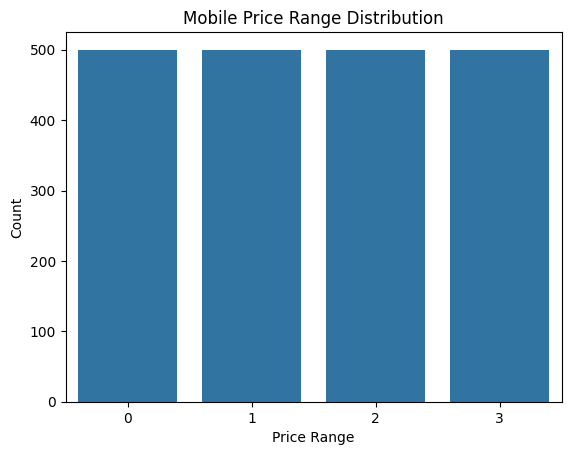

In [75]:
# Create a count plot to visualize the distribution of 'price_range'
sns.countplot(x='price_range', data=df)

# Configure plot title and labels
plt.title("Mobile Price Range Distribution")
plt.xlabel("Price Range")
plt.ylabel("Count")

# Render the plot
plt.show()

Observation: The four price categories contain 500 records each in the standard cellphone price classification dataset.

### 9.2 Univariate Analysis – Histograms

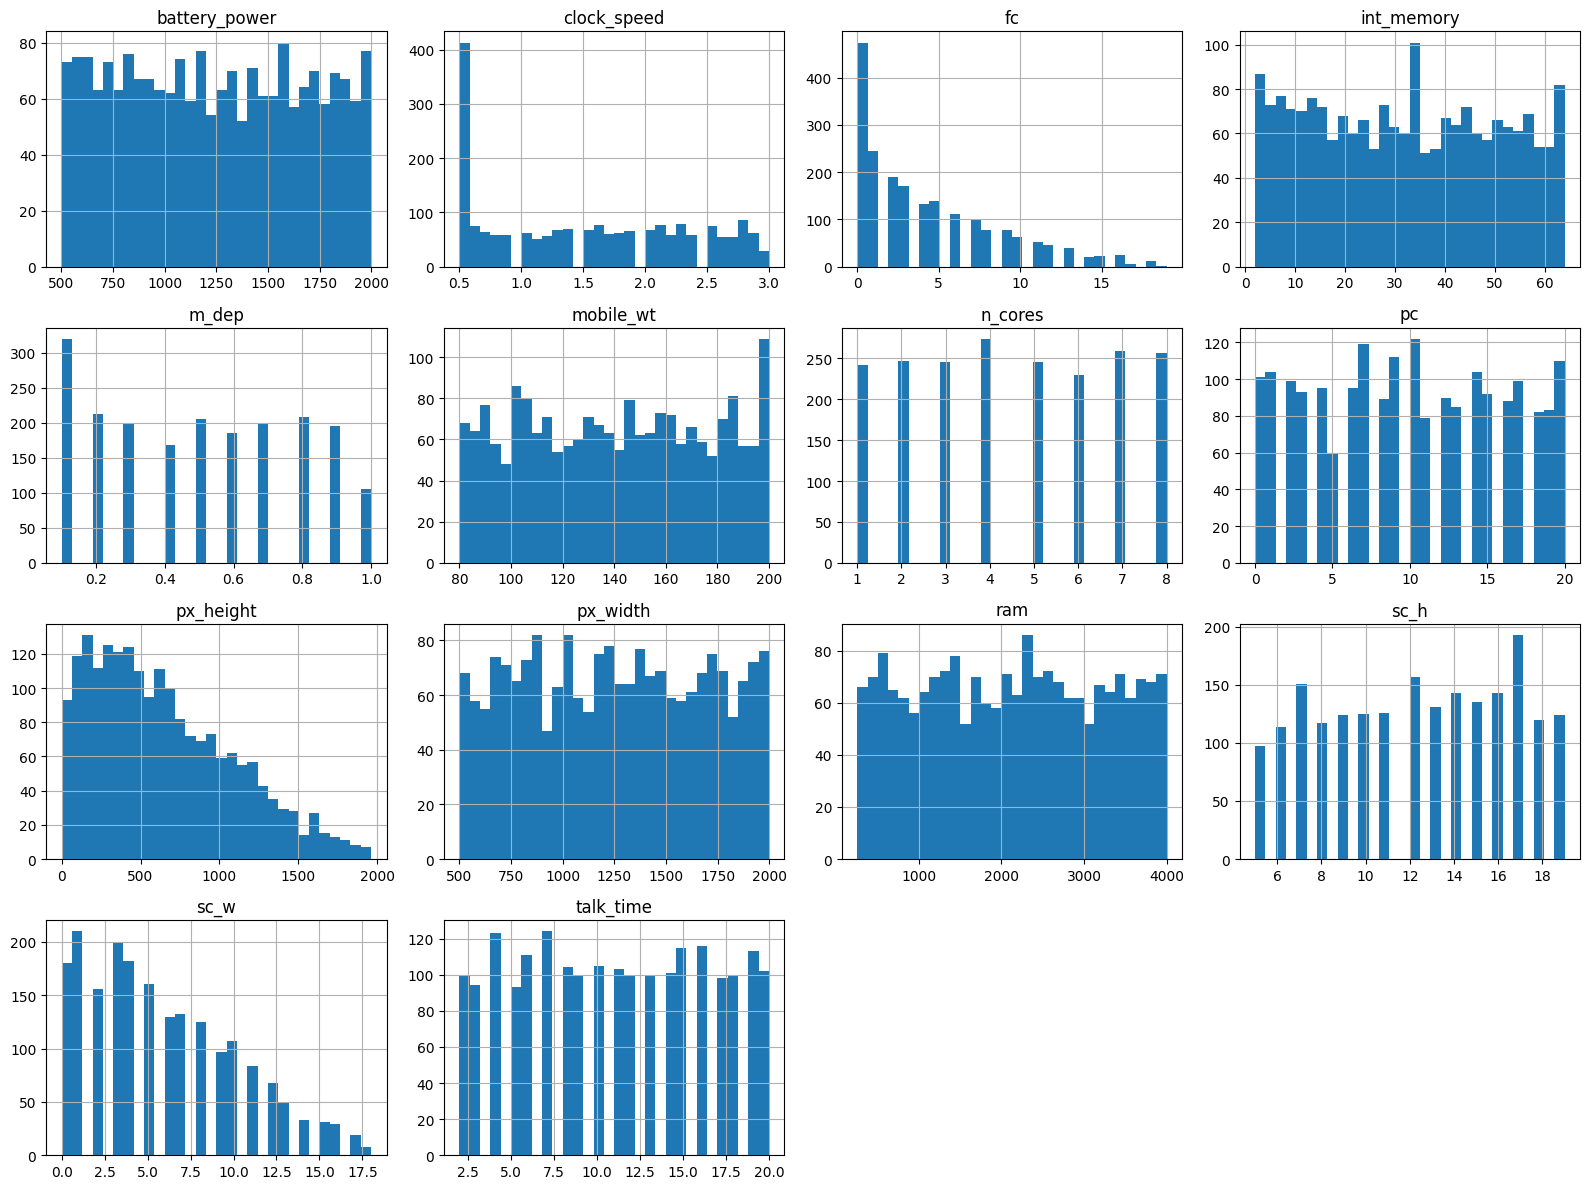

In [76]:
# List of all continuous/numerical features in the dataset
numerical_cols = [
    'battery_power',
    'clock_speed',
    'fc',
    'int_memory',
    'm_dep',
    'mobile_wt',
    'n_cores',
    'pc',
    'px_height',
    'px_width',
    'ram',
    'sc_h',
    'sc_w',
    'talk_time'
]

# Generate histograms for all numerical features to inspect their distributions
df[numerical_cols].hist(
    figsize=(16, 12),
    bins=30
)

# Adjust subplot parameters to fit nicely within the figure and show the plot
plt.tight_layout()
plt.show()

Observation:

Histograms help understand the distribution of individual features.

Some features, such as front camera megapixels and pixel height, show positively skewed distributions.

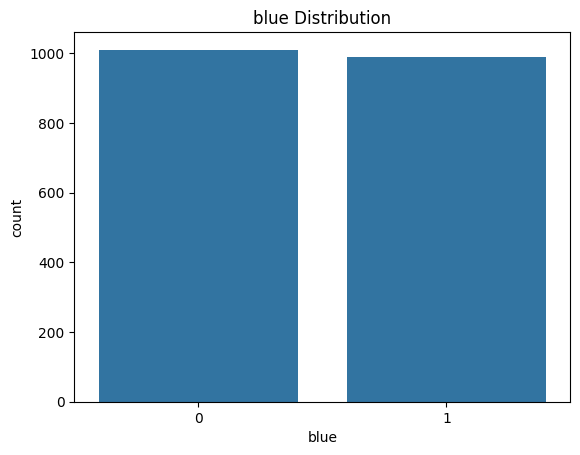

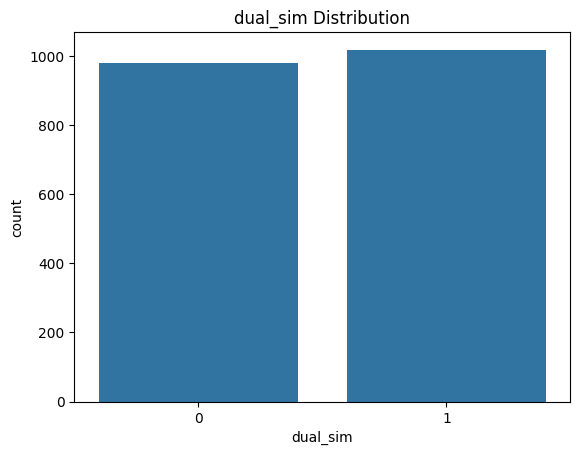

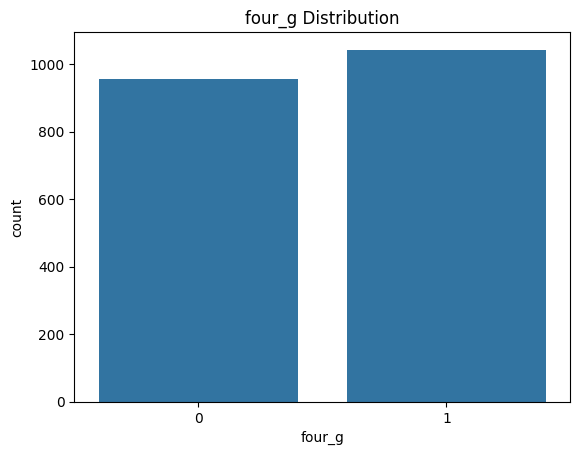

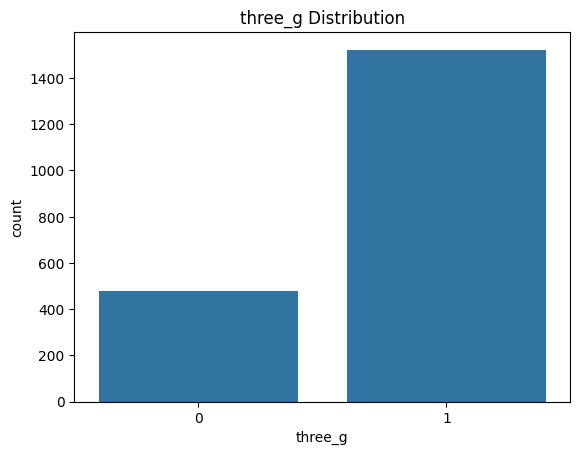

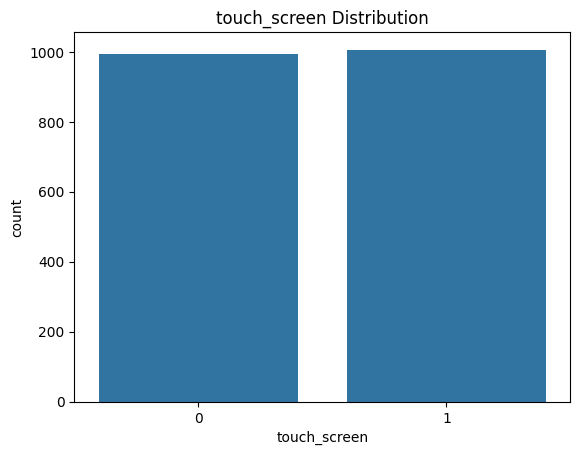

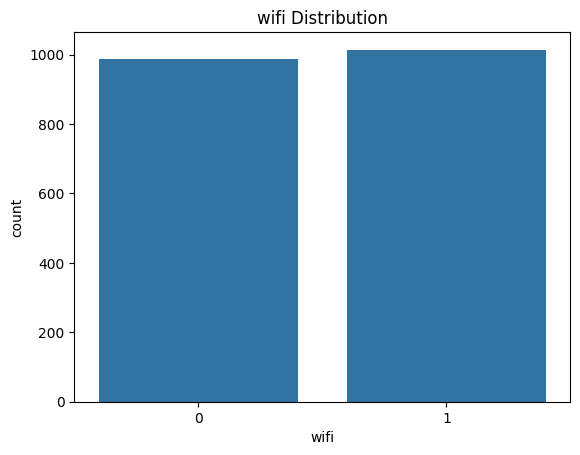

In [78]:
# Define the categorical/binary columns
binary_cols = [
    'blue',
    'dual_sim',
    'four_g',
    'three_g',
    'touch_screen',
    'wifi'
]

# Loop through each binary column and display its distribution
for col in binary_cols:
    sns.countplot(x=col, data=df)
    plt.title(f'{col} Distribution')
    plt.show()

### 9.3 Boxplots

 Boxplots were used to identify potential outliers in the numerical features.

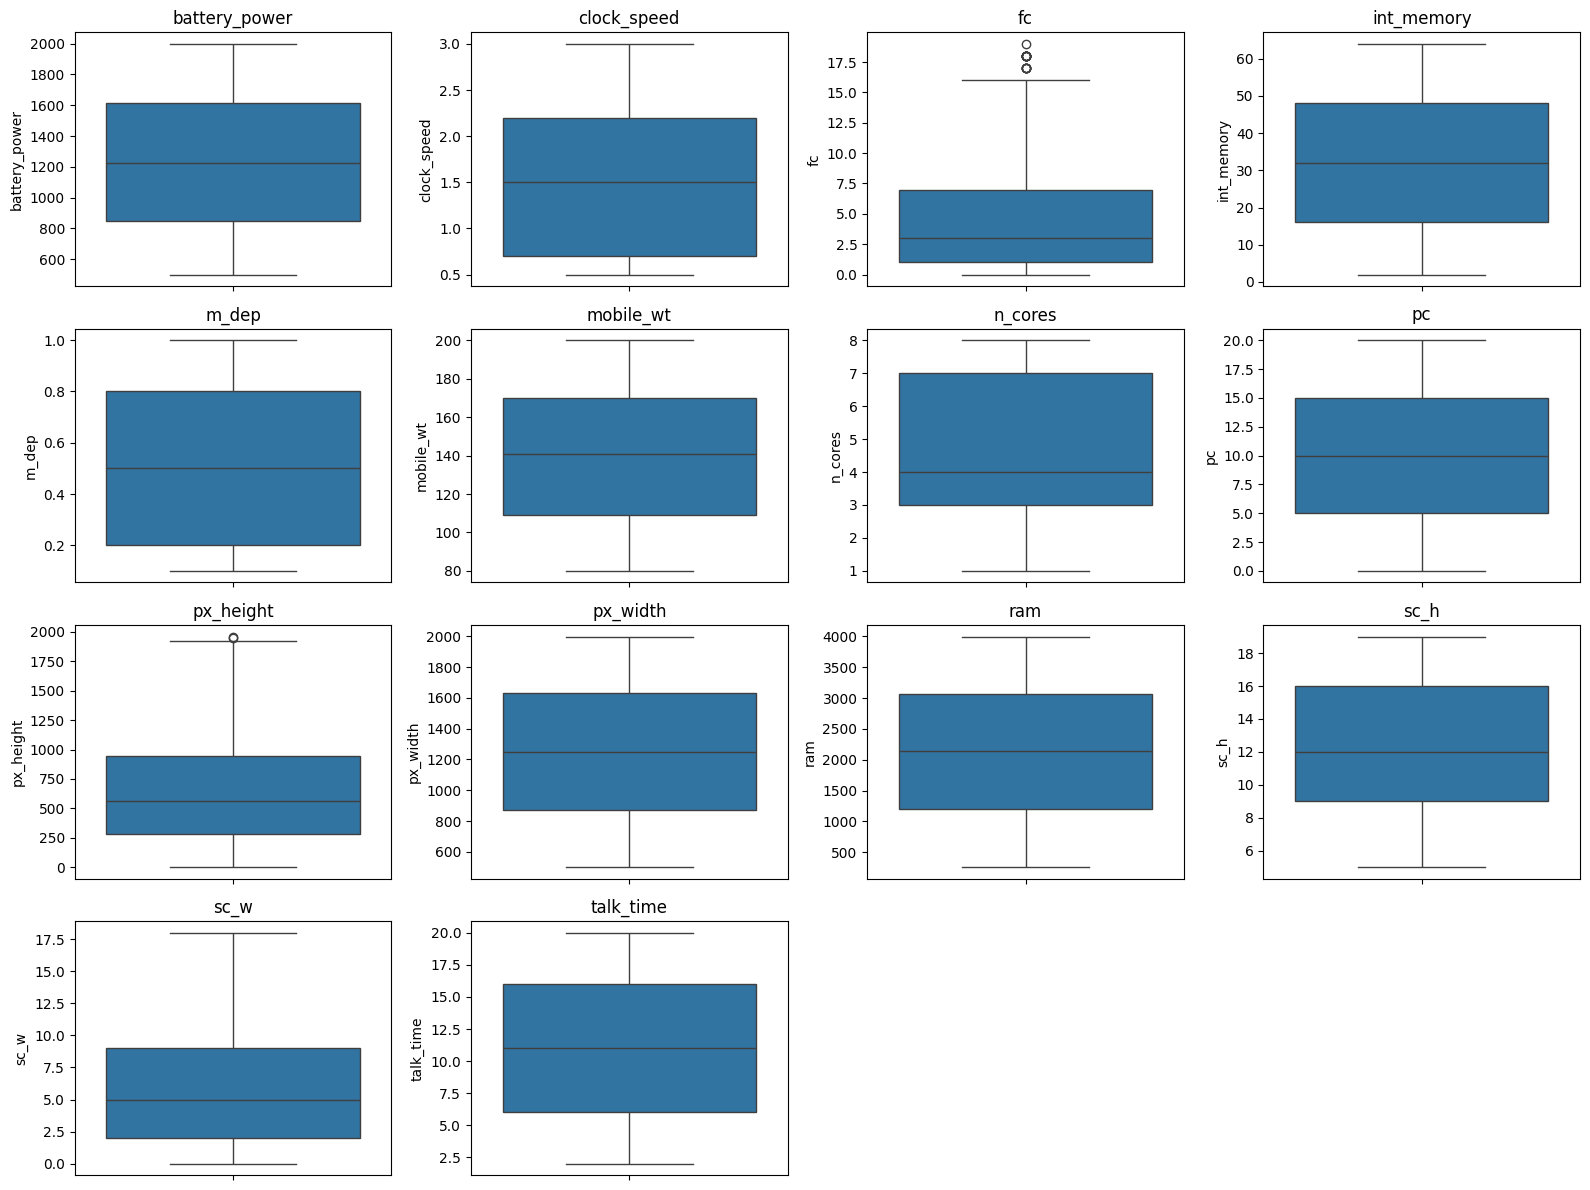

In [77]:
# Set the figure size for individual boxplots of numerical columns
plt.figure(figsize=(16, 12))

# Loop through each numerical column to create separate boxplots to check for outliers
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(4, 4, i)
    sns.boxplot(y=df[col])
    plt.title(col)

# Optimize layout and show the boxplots
plt.tight_layout()
plt.show()

### 9.4 Bivariate Analysis

RAM vs Price Range

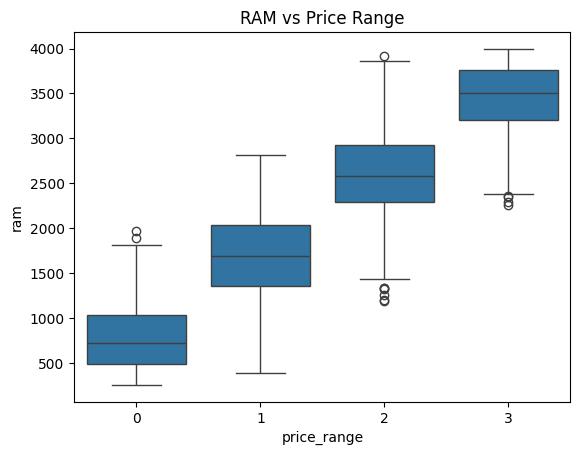

In [79]:
# Analyze the relationship between 'ram' and 'price_range' using a boxplot
sns.boxplot(
    x='price_range',
    y='ram',
    data=df
)

# Set the title and render the plot
plt.title("RAM vs Price Range")
plt.show()

battery power vs price range

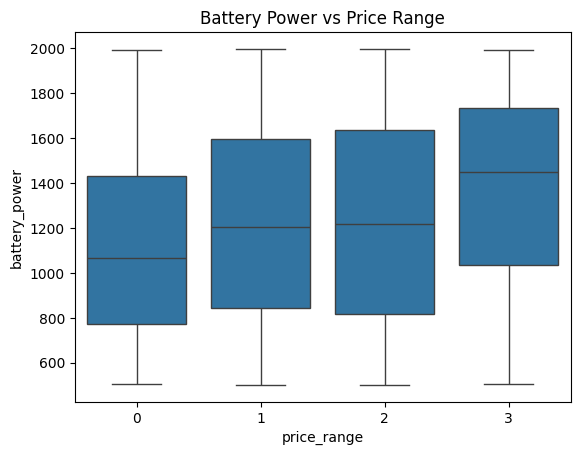

In [80]:
# Analyze the relationship between 'battery_power' and 'price_range' using a boxplot
sns.boxplot(
    x='price_range',
    y='battery_power',
    data=df
)

# Set the title and render the plot
plt.title("Battery Power vs Price Range")
plt.show()

int memory vs price range

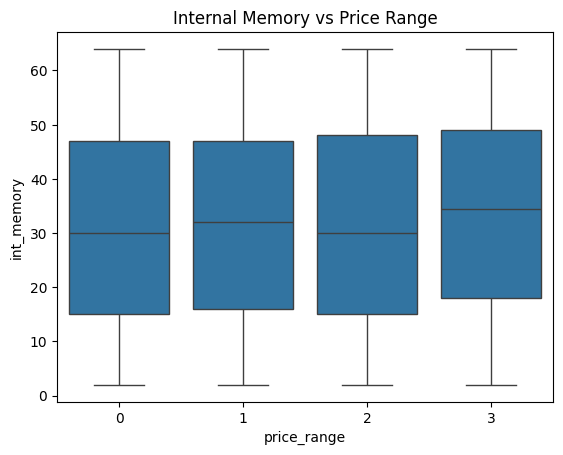

In [81]:
# Analyze the relationship between 'int_memory' and 'price_range' using a boxplot
sns.boxplot(
    x='price_range',
    y='int_memory',
    data=df
)

# Set the title and render the plot
plt.title("Internal Memory vs Price Range")
plt.show()

### 9.5 Correlation Heatmap

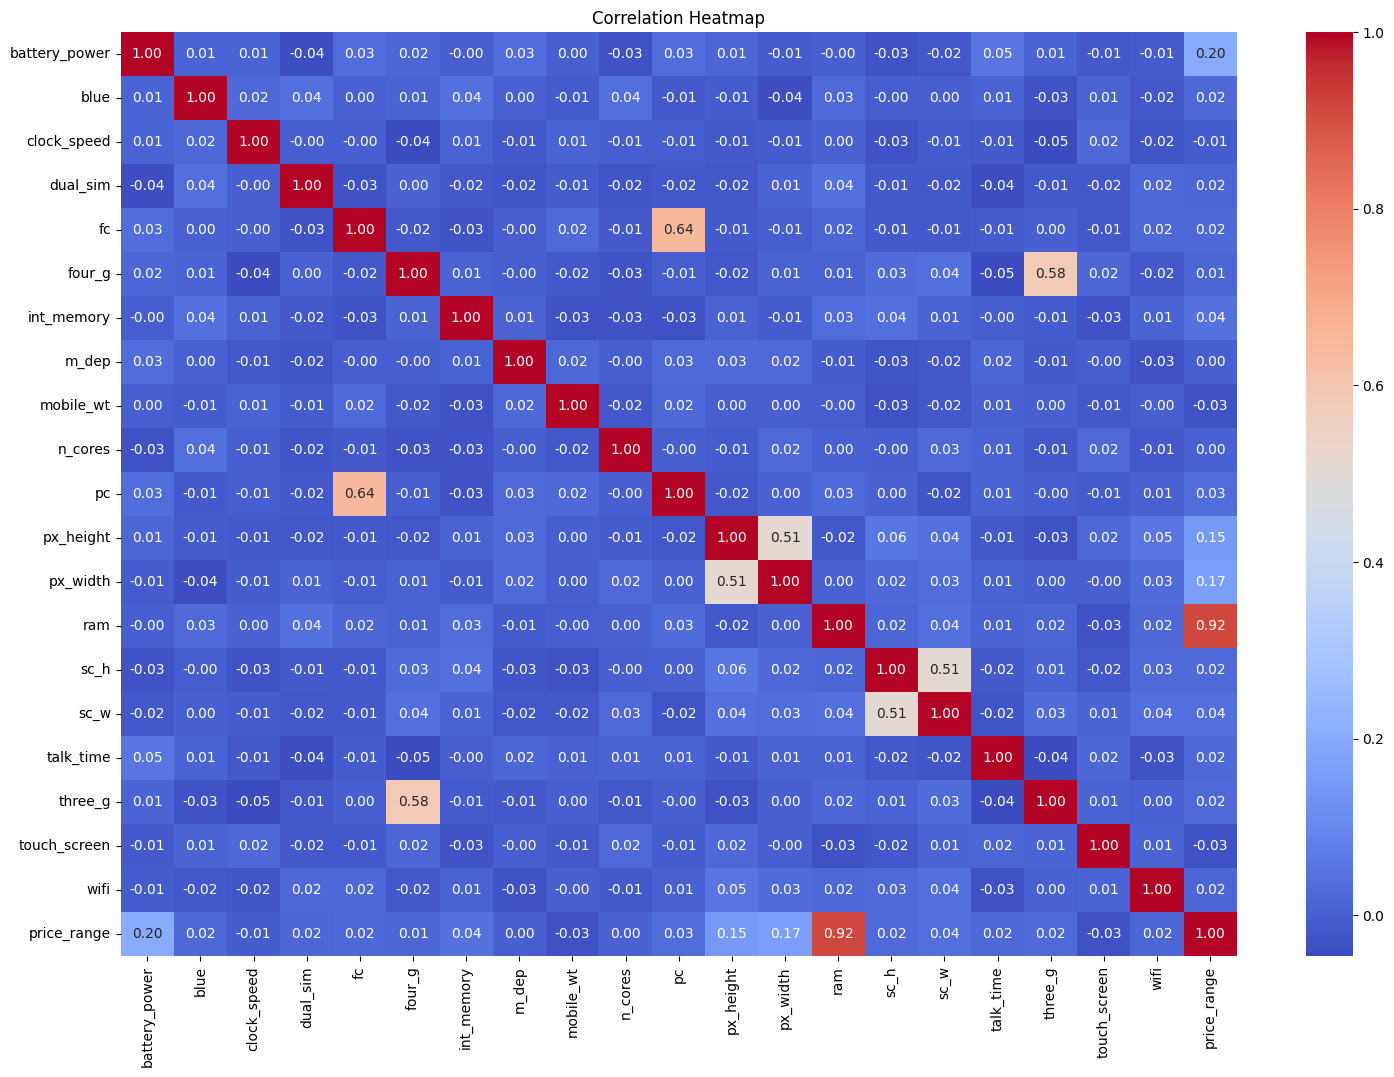

In [82]:
# Set a large figure size for the correlation matrix heatmap
plt.figure(figsize=(18, 12))

# Plot a heatmap of the Pearson correlation coefficient between all features
sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

# Set the title and render the plot
plt.title("Correlation Heatmap")
plt.show()

Observation:

RAM has a strong positive correlation with price range, approximately 0.92.

Battery power has a positive correlation of approximately 0.20.

Pixel height has a positive correlation of approximately 0.15.

Pixel width has a positive correlation of approximately 0.17.

RAM is strongly associated with cellphone price range.

Correlation measures linear association and does not necessarily indicate causation.

## 10. Outlier Detection Using IQR

The Interquartile Range method was used to identify potential outliers.

Formula:

IQR = Q3 − Q1

Lower limit = Q1 − 1.5 × IQR

Upper limit = Q3 + 1.5 × IQR

In [83]:
# Programmatically find outliers using the Interquartile Range (IQR) method
for col in numerical_cols:
    # Calculate the 1st and 3rd quartiles
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    # Calculate Interquartile Range
    IQR = Q3 - Q1

    # Establish lower and upper outlier bounds
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Filter the outliers
    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    # Print the count of outliers identified in each numerical column
    print(col, ":", len(outliers))

battery_power : 0
clock_speed : 0
fc : 18
int_memory : 0
m_dep : 0
mobile_wt : 0
n_cores : 0
pc : 0
px_height : 2
px_width : 0
ram : 0
sc_h : 0
sc_w : 0
talk_time : 0


### Outlier Analysis – Observation

The Interquartile Range (IQR) method was used to identify potential outliers in numerical features.

The analysis identified:
- Front Camera (fc): 18 potential outliers.
- Pixel Height (px_height): 2 potential outliers.

All remaining numerical features showed zero potential outliers.

These observations were not removed because they may represent valid mobile phone specifications. Therefore, all original records were retained for further analysis and model development.

In [84]:
# Measure and sort the skewness of each numerical feature in descending order
df[numerical_cols].skew().sort_values(ascending=False)

,0
fc,1.019811
px_height,0.666271
sc_w,0.633787
clock_speed,0.178084
m_dep,0.089082
int_memory,0.057889
battery_power,0.031898
pc,0.017306
px_width,0.014787
talk_time,0.009512


### Skewness Analysis – Observation

Skewness was calculated for all numerical features to understand their distributions.

The analysis showed that:

- Front Camera (fc) has positive skewness of 1.0198.
- Pixel Height (px_height) has positive skewness of 0.6663.
- Screen Width (sc_w) has positive skewness of 0.6938.
- The remaining numerical features are approximately symmetrical.

Log transformation was not applied because the skewed features contain valid mobile specifications, and tree-based algorithms do not require normally distributed input features.

All original feature values were retained for further model development.

## 11. Feature and Target Separation

Independent variables (X) contain cellphone specifications.

The dependent variable (y) contains the price range.

In [85]:
# Separate the target label ('price_range') from the independent features
X = df.drop('price_range', axis=1)
y = df['price_range']

In [86]:
# Print the feature matrix (X) shape and the target series (y) shape
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2000, 20)
y shape: (2000,)


## 12. Train-Test Split

The dataset is divided into training and testing data.

Training data: 80%

Testing data: 20%

Random state: 42

In [87]:
from sklearn.model_selection import train_test_split

# Split the dataset into 80% training and 20% test subsets.
# stratify=y ensures identical target distribution across train and test sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [88]:
# Output the final dimensions of training and test matrices and series
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1600, 20)
X_test: (400, 20)
y_train: (1600,)
y_test: (400,)


## 13. Feature Scaling

StandardScaler is used to standardize the numerical features.

It is useful for Logistic Regression, KNN, and SVM.

The scaler is fitted only on training data.

In [89]:
from sklearn.preprocessing import StandardScaler

# Initialize the standard scaler to normalize features to mean=0 and variance=1
scaler = StandardScaler()

# Fit on the training set and transform both training and test feature sets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 14. Model Building

Seven classification algorithms are implemented.

### 1.Logistic Regression

Definition: Logistic Regression is a supervised classification algorithm that predicts the probability of a class using a logistic function.

In [90]:
# Initialize Logistic Regression with a higher max_iter limit for convergence
lr = LogisticRegression(max_iter=1000)

# Train the Logistic Regression model on the scaled training data
lr.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [91]:
# Perform predictions on the scaled test set using the trained Logistic Regression model
y_pred_lr = lr.predict(X_test_scaled)

In [92]:
# Display the predicted class array for Logistic Regression
y_pred_lr

array([3, 1, 0, 2, 3, 2, 0, 0, 1, 0, 3, 0, 0, 1, 3, 3, 2, 0, 1, 3, 1, 0,
       3, 2, 2, 1, 1, 0, 2, 1, 1, 2, 0, 2, 2, 3, 0, 3, 1, 0, 2, 0, 0, 2,
       3, 0, 3, 3, 2, 1, 0, 3, 0, 2, 0, 3, 3, 0, 2, 1, 1, 2, 3, 1, 0, 1,
       0, 1, 3, 3, 3, 2, 1, 1, 2, 0, 3, 3, 1, 3, 3, 2, 2, 0, 0, 1, 0, 0,
       0, 0, 0, 2, 2, 3, 0, 3, 0, 0, 2, 2, 3, 1, 1, 0, 3, 3, 1, 2, 1, 1,
       0, 2, 3, 1, 3, 2, 2, 2, 2, 2, 2, 0, 3, 0, 3, 3, 2, 0, 2, 3, 3, 0,
       0, 1, 3, 1, 2, 3, 2, 3, 3, 3, 2, 1, 3, 2, 1, 1, 0, 1, 3, 0, 1, 1,
       3, 3, 3, 2, 0, 2, 2, 0, 0, 3, 1, 1, 3, 2, 3, 0, 1, 1, 1, 3, 2, 1,
       1, 3, 0, 3, 2, 2, 2, 3, 0, 2, 0, 1, 1, 1, 0, 2, 1, 2, 3, 0, 2, 3,
       1, 1, 1, 2, 1, 2, 0, 0, 3, 1, 1, 2, 1, 3, 2, 0, 0, 3, 1, 2, 3, 3,
       0, 3, 3, 2, 2, 1, 1, 2, 1, 1, 0, 2, 0, 0, 0, 0, 0, 2, 2, 2, 2, 3,
       0, 1, 3, 2, 2, 3, 3, 2, 1, 0, 3, 3, 1, 3, 2, 2, 2, 2, 2, 2, 2, 1,
       0, 0, 3, 1, 2, 3, 3, 0, 0, 0, 1, 3, 2, 2, 3, 1, 3, 2, 2, 1, 1, 0,
       1, 1, 1, 3, 1, 0, 3, 1, 1, 1, 0, 1, 1, 1, 1,

## 2. K-Nearest Neighbors (KNN)

Definition: KNN predicts the class of a new data point based on the majority class among its nearest neighbours.

In [93]:
# Initialize and train K-Neighbors Classifier using 5 neighbors
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [94]:
# Predict classes for the test set using the KNN model
y_pred_knn = knn.predict(X_test_scaled)

In [95]:
# Display the predicted class array for KNN
y_pred_knn

array([3, 2, 0, 1, 2, 2, 1, 1, 0, 1, 2, 0, 1, 1, 2, 3, 2, 0, 3, 2, 2, 0,
       3, 1, 2, 1, 1, 0, 1, 0, 1, 2, 0, 2, 1, 3, 1, 2, 0, 0, 0, 0, 1, 2,
       3, 0, 2, 2, 2, 2, 0, 2, 0, 2, 1, 1, 2, 0, 3, 3, 1, 1, 3, 0, 0, 0,
       1, 1, 1, 3, 3, 1, 0, 1, 2, 1, 2, 2, 0, 1, 3, 1, 2, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 3, 2, 0, 1, 2, 0, 3, 1, 1, 0, 2, 0, 3, 3, 0, 2, 1, 1,
       0, 1, 3, 3, 3, 2, 1, 3, 1, 1, 1, 0, 3, 1, 2, 3, 2, 0, 3, 3, 2, 0,
       0, 2, 1, 0, 1, 3, 0, 3, 3, 3, 1, 0, 3, 2, 2, 1, 0, 2, 3, 0, 1, 0,
       3, 3, 1, 2, 0, 1, 1, 0, 0, 3, 3, 1, 3, 1, 2, 0, 0, 2, 1, 2, 1, 1,
       0, 3, 0, 2, 0, 1, 3, 3, 0, 1, 0, 1, 0, 0, 1, 3, 1, 2, 2, 0, 1, 1,
       0, 1, 2, 1, 3, 2, 0, 0, 2, 0, 0, 3, 1, 3, 2, 0, 0, 2, 2, 1, 3, 2,
       0, 3, 0, 1, 1, 1, 1, 2, 2, 0, 0, 1, 0, 0, 0, 1, 1, 2, 1, 3, 2, 2,
       0, 0, 3, 2, 1, 3, 3, 2, 2, 1, 3, 3, 1, 2, 2, 2, 2, 1, 2, 1, 2, 1,
       1, 0, 1, 0, 2, 3, 1, 0, 0, 0, 2, 3, 2, 2, 3, 1, 3, 2, 2, 1, 0, 0,
       1, 0, 1, 3, 0, 0, 3, 2, 0, 2, 1, 1, 1, 2, 1,

## 3. Decision Tree
Definition: Decision Tree is a supervised learning algorithm that makes predictions using a tree-like structure of decision rules.

In [96]:
# Initialize and train a Decision Tree Classifier (does not require scaling)
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [97]:
# Predict classes for the test set using the Decision Tree model
y_pred_dt = dt.predict(X_test)

In [98]:
# Display the predicted class array for the Decision Tree
y_pred_dt

array([3, 2, 0, 2, 3, 2, 0, 0, 1, 0, 3, 0, 0, 1, 3, 3, 2, 0, 1, 2, 1, 0,
       3, 2, 2, 1, 1, 0, 2, 1, 0, 2, 0, 2, 2, 3, 0, 3, 1, 0, 2, 0, 0, 2,
       3, 0, 3, 3, 3, 2, 0, 3, 0, 2, 0, 3, 3, 0, 2, 1, 1, 2, 3, 1, 1, 0,
       0, 1, 3, 3, 3, 2, 1, 2, 2, 0, 2, 3, 1, 2, 3, 2, 2, 0, 0, 1, 0, 0,
       0, 1, 0, 2, 2, 3, 0, 3, 1, 0, 1, 2, 3, 1, 1, 1, 3, 3, 2, 2, 1, 1,
       0, 2, 3, 1, 3, 2, 2, 2, 2, 2, 3, 0, 3, 0, 2, 3, 2, 1, 3, 3, 3, 0,
       0, 2, 2, 1, 2, 3, 1, 3, 3, 3, 2, 1, 3, 2, 1, 1, 0, 0, 3, 0, 0, 0,
       3, 3, 3, 2, 1, 1, 1, 0, 0, 3, 1, 1, 2, 2, 3, 0, 1, 1, 1, 3, 3, 1,
       0, 3, 0, 3, 1, 2, 2, 3, 0, 2, 0, 1, 1, 1, 0, 2, 1, 2, 3, 0, 2, 3,
       1, 1, 1, 2, 0, 2, 0, 0, 3, 1, 1, 1, 0, 2, 2, 0, 0, 3, 1, 1, 3, 3,
       0, 3, 2, 2, 2, 2, 2, 2, 0, 1, 0, 2, 0, 0, 0, 0, 0, 2, 2, 3, 2, 3,
       0, 1, 3, 2, 2, 3, 3, 2, 2, 0, 3, 3, 1, 3, 2, 2, 1, 2, 2, 2, 2, 1,
       0, 0, 3, 0, 2, 3, 2, 0, 0, 0, 1, 3, 1, 2, 3, 1, 3, 2, 2, 2, 1, 0,
       1, 1, 1, 3, 1, 0, 3, 1, 1, 1, 0, 0, 1, 1, 0,

## 4. Random Forest
Definition: Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve prediction performance.

In [99]:
# Initialize and train a Random Forest Classifier with 100 trees
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [100]:
# Predict classes for the test set using the Random Forest model
y_pred_rf = rf.predict(X_test)

In [101]:
# Display the predicted class array for the Random Forest
y_pred_rf

array([3, 1, 0, 2, 3, 2, 0, 0, 1, 0, 3, 0, 0, 1, 3, 3, 2, 0, 1, 3, 1, 0,
       3, 2, 2, 1, 1, 0, 2, 1, 1, 2, 0, 2, 2, 3, 0, 3, 1, 0, 2, 0, 0, 2,
       3, 0, 3, 3, 2, 2, 0, 3, 0, 2, 0, 3, 3, 0, 2, 1, 1, 2, 3, 1, 0, 0,
       0, 1, 3, 3, 3, 2, 1, 1, 2, 1, 3, 3, 1, 3, 3, 2, 2, 0, 0, 1, 0, 0,
       0, 1, 0, 2, 2, 2, 0, 3, 0, 0, 2, 2, 3, 1, 1, 0, 3, 3, 1, 2, 1, 1,
       0, 2, 3, 1, 3, 2, 2, 3, 2, 2, 3, 0, 3, 0, 2, 3, 2, 1, 2, 3, 3, 0,
       0, 2, 3, 1, 1, 3, 2, 3, 3, 3, 2, 1, 3, 2, 1, 1, 0, 1, 3, 0, 1, 1,
       3, 3, 3, 2, 0, 2, 1, 0, 0, 3, 1, 1, 2, 1, 3, 0, 1, 1, 1, 3, 2, 1,
       0, 3, 0, 3, 2, 2, 2, 3, 0, 2, 0, 1, 1, 1, 0, 2, 1, 2, 3, 0, 2, 3,
       1, 1, 1, 2, 0, 3, 0, 0, 3, 1, 1, 1, 0, 2, 2, 0, 0, 3, 1, 2, 3, 3,
       0, 3, 2, 1, 2, 1, 1, 2, 1, 1, 0, 1, 0, 0, 0, 0, 0, 2, 1, 3, 2, 3,
       0, 1, 3, 1, 2, 3, 3, 2, 1, 0, 3, 3, 1, 3, 2, 1, 1, 2, 2, 2, 3, 1,
       0, 0, 3, 1, 2, 3, 2, 0, 0, 0, 1, 3, 2, 2, 3, 1, 3, 2, 2, 2, 1, 0,
       1, 1, 2, 3, 1, 0, 3, 1, 1, 1, 0, 1, 1, 2, 1,

## 5. Support Vector Machine (SVM)
Definition: SVM is a supervised learning algorithm that finds an optimal decision boundary to separate different classes.

In [102]:
# Initialize and train a Support Vector Classifier using a Radial Basis Function kernel
svm = SVC(kernel='rbf')
svm.fit(X_train_scaled, y_train)

SVC()

In [103]:
# Predict classes for the test set using the SVM model
y_pred_svm = svm.predict(X_test_scaled)

In [104]:
# Display the predicted class array for SVM
y_pred_svm

array([3, 1, 0, 1, 3, 2, 0, 0, 1, 0, 3, 0, 0, 1, 3, 3, 2, 0, 1, 3, 1, 0,
       3, 2, 2, 1, 1, 0, 2, 1, 1, 2, 0, 2, 2, 3, 0, 2, 2, 0, 2, 0, 0, 2,
       3, 0, 3, 3, 2, 1, 0, 3, 0, 2, 0, 3, 3, 0, 2, 2, 1, 2, 3, 1, 0, 1,
       0, 1, 3, 3, 3, 2, 0, 1, 2, 1, 2, 2, 2, 2, 3, 2, 2, 0, 0, 1, 0, 0,
       0, 0, 0, 2, 1, 2, 0, 3, 0, 0, 2, 2, 3, 1, 1, 0, 3, 3, 1, 2, 1, 1,
       0, 2, 3, 2, 3, 2, 2, 3, 2, 2, 2, 0, 3, 0, 2, 3, 2, 1, 2, 3, 3, 0,
       0, 2, 3, 1, 1, 3, 2, 3, 3, 3, 2, 1, 3, 2, 1, 1, 0, 0, 3, 0, 1, 1,
       3, 3, 3, 3, 0, 2, 1, 1, 0, 3, 1, 1, 3, 2, 3, 0, 1, 1, 1, 3, 2, 1,
       1, 3, 0, 3, 2, 2, 2, 3, 0, 2, 0, 1, 1, 1, 0, 2, 1, 2, 3, 0, 2, 3,
       1, 1, 1, 3, 0, 3, 0, 0, 3, 1, 2, 2, 1, 3, 2, 0, 0, 3, 1, 2, 3, 3,
       0, 3, 2, 2, 1, 1, 1, 2, 1, 1, 0, 2, 0, 0, 0, 0, 1, 2, 2, 2, 2, 2,
       0, 1, 3, 2, 2, 3, 3, 2, 1, 0, 3, 3, 1, 3, 2, 1, 2, 2, 2, 2, 2, 1,
       0, 0, 3, 1, 2, 3, 3, 0, 0, 0, 1, 3, 2, 2, 3, 1, 3, 2, 2, 1, 1, 0,
       1, 1, 1, 3, 1, 0, 3, 1, 1, 1, 0, 1, 1, 2, 1,

## 6. Gaussian Naive Bayes
Definition: Naive Bayes is a probabilistic classification algorithm based on Bayes' theorem. Gaussian Naive Bayes assumes that features follow a Gaussian distribution within each class.

In [105]:
# Initialize and train a Gaussian Naive Bayes classifier
nb = GaussianNB()
nb.fit(X_train, y_train)

GaussianNB()

In [106]:
# Predict classes for the test set using the Naive Bayes model
y_pred_nb = nb.predict(X_test)

In [107]:
# Display the predicted class array for Naive Bayes
y_pred_nb

array([3, 1, 0, 1, 3, 2, 0, 0, 1, 0, 3, 0, 0, 1, 3, 3, 2, 1, 1, 3, 1, 0,
       3, 3, 2, 1, 2, 0, 2, 1, 1, 1, 0, 2, 2, 3, 0, 3, 2, 0, 2, 0, 0, 2,
       3, 0, 3, 3, 2, 2, 0, 3, 0, 2, 0, 3, 3, 0, 2, 1, 1, 2, 3, 1, 0, 0,
       0, 2, 3, 3, 3, 2, 1, 1, 2, 1, 3, 3, 2, 3, 3, 2, 2, 0, 0, 2, 0, 0,
       0, 1, 0, 3, 2, 2, 0, 3, 0, 0, 2, 2, 3, 1, 1, 1, 3, 3, 1, 2, 1, 1,
       0, 2, 3, 2, 3, 2, 2, 3, 1, 2, 3, 0, 3, 0, 3, 3, 2, 0, 3, 3, 3, 0,
       0, 2, 3, 1, 2, 3, 2, 3, 3, 3, 2, 1, 3, 3, 1, 1, 0, 0, 3, 0, 1, 1,
       3, 3, 3, 2, 1, 1, 1, 0, 0, 3, 1, 2, 3, 1, 3, 0, 1, 1, 1, 3, 2, 1,
       1, 3, 0, 3, 2, 2, 2, 3, 0, 2, 0, 1, 1, 1, 0, 2, 1, 2, 3, 0, 2, 3,
       1, 1, 1, 2, 1, 3, 0, 0, 3, 1, 1, 2, 0, 3, 1, 0, 0, 3, 1, 2, 3, 3,
       0, 3, 2, 1, 2, 1, 1, 2, 0, 1, 0, 1, 0, 0, 1, 0, 0, 3, 2, 2, 2, 2,
       0, 1, 3, 2, 2, 3, 3, 1, 1, 0, 3, 3, 1, 3, 2, 1, 1, 1, 2, 2, 3, 1,
       1, 0, 3, 1, 2, 3, 2, 0, 0, 0, 1, 3, 2, 2, 3, 1, 3, 2, 2, 1, 1, 0,
       1, 2, 2, 3, 1, 0, 3, 1, 1, 1, 0, 0, 2, 2, 1,

## 7. XGBoost
Definition: XGBoost is an ensemble learning algorithm based on gradient boosting. It builds trees sequentially, with each new tree attempting to correct errors made by previous trees.

In [108]:
# Initialize and train an XGBoost classifier for multiclass tracking
xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
    eval_metric='mlogloss'
)
xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='mlogloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, ...)

In [109]:
# Predict classes for the test set using the XGBoost model
y_pred_xgb = xgb.predict(X_test)

In [110]:
# Display the predicted class array for XGBoost
y_pred_xgb

array([3, 1, 0, 2, 3, 2, 0, 0, 1, 0, 3, 0, 0, 1, 3, 3, 2, 0, 1, 3, 1, 0,
       3, 2, 2, 1, 1, 0, 2, 1, 0, 2, 0, 2, 2, 3, 0, 3, 1, 0, 2, 0, 0, 2,
       3, 0, 3, 3, 3, 1, 0, 3, 0, 2, 0, 3, 3, 0, 2, 1, 1, 2, 3, 1, 0, 1,
       0, 1, 3, 3, 3, 2, 1, 1, 2, 0, 3, 3, 1, 2, 3, 2, 2, 0, 0, 2, 0, 0,
       0, 1, 0, 2, 2, 2, 0, 3, 0, 0, 2, 2, 3, 1, 1, 0, 3, 3, 1, 2, 1, 1,
       0, 2, 3, 1, 3, 2, 2, 2, 2, 2, 3, 0, 3, 0, 3, 3, 2, 0, 2, 3, 3, 0,
       0, 1, 3, 1, 1, 3, 2, 3, 3, 3, 2, 1, 3, 2, 1, 1, 0, 0, 3, 0, 0, 1,
       3, 3, 3, 2, 0, 2, 1, 0, 0, 3, 1, 1, 2, 1, 3, 0, 1, 1, 1, 3, 2, 1,
       1, 3, 0, 3, 2, 2, 2, 3, 0, 2, 0, 1, 1, 1, 0, 2, 1, 2, 3, 0, 2, 3,
       1, 1, 1, 2, 1, 3, 0, 0, 3, 1, 1, 1, 0, 3, 2, 0, 0, 3, 1, 2, 3, 3,
       0, 3, 2, 2, 2, 1, 1, 2, 0, 1, 0, 2, 0, 0, 0, 0, 0, 2, 2, 2, 2, 3,
       0, 1, 3, 1, 2, 3, 3, 2, 1, 0, 3, 3, 1, 3, 2, 1, 1, 2, 2, 2, 2, 1,
       0, 0, 3, 1, 2, 3, 2, 0, 0, 0, 1, 3, 2, 2, 3, 1, 3, 2, 2, 1, 1, 0,
       1, 1, 2, 3, 1, 0, 3, 1, 1, 1, 0, 1, 1, 2, 1,

## 15. Model evaluation
Classification models were evaluated using the following metrics.

Accuracy - Overall percentage of correct predictions

Precision - How many predicted positive cases were actually positive

Recall - How many actual positive cases were correctly identified

F1-score -Harmonic mean of precision and recall

In [111]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Map each model name to its predicted outcomes
models = {
    'Logistic Regression': y_pred_lr,
    'KNN': y_pred_knn,
    'Decision Tree': y_pred_dt,
    'Random Forest': y_pred_rf,
    'SVM': y_pred_svm,
    'Naive Bayes': y_pred_nb,
    'XGBoost': y_pred_xgb
}

results = []

# Calculate metrics (Accuracy, Precision, Recall, F1-Score) for all trained classifiers
for name, y_pred in models.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(
            y_test, y_pred, average='weighted'
        ),
        'Recall': recall_score(
            y_test, y_pred, average='weighted'
        ),
        'F1 Score': f1_score(
            y_test, y_pred, average='weighted'
        )
    })

# Put results into a DataFrame and sort it by F1-Score in descending order
results_df = pd.DataFrame(results)
results_df.sort_values(
    by='F1 Score',
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.9650,0.965045,0.9650,0.964986
6,XGBoost,0.9125,0.911838,0.9125,0.911930
4,SVM,0.8950,0.896860,0.8950,0.895631
3,Random Forest,0.8800,0.879614,0.8800,0.879734
2,Decision Tree,0.8300,0.831883,0.8300,0.830168
5,Naive Bayes,0.8100,0.811326,0.8100,0.810458
1,KNN,0.5000,0.521130,0.5000,0.505355


Model Accuracy Comparison Graph

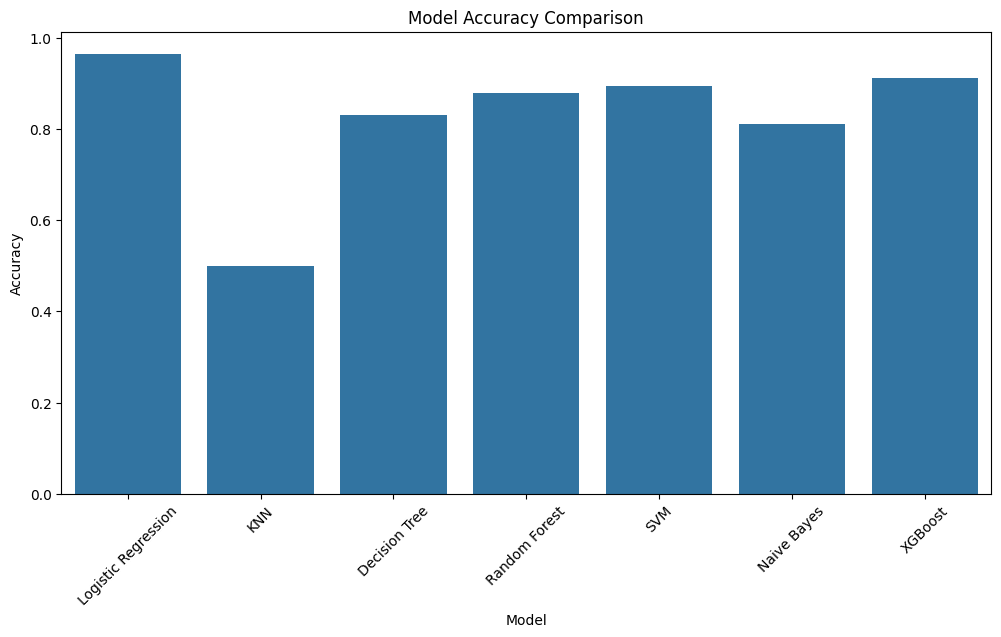

In [112]:
# Set figure size
plt.figure(figsize=(12, 6))

# Create a bar plot to compare classification accuracies across models
sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy'
)

# Set labels and title
plt.xticks(rotation=45)
plt.title('Model Accuracy Comparison')
plt.show()

## 16. Confusion Matrix

The confusion matrix helps understand correct and incorrect predictions for each price category.

## Logistic Regression

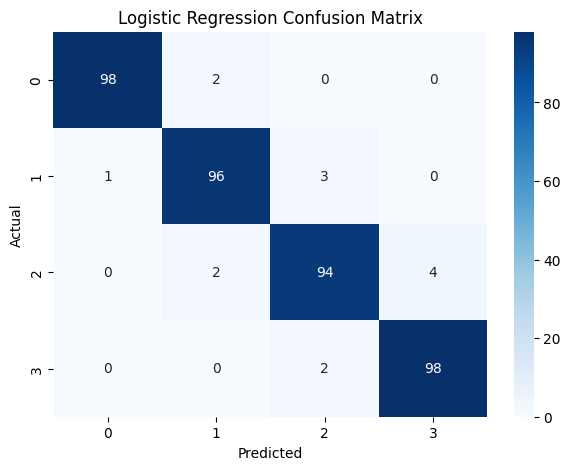

In [114]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generate confusion matrix for baseline Logistic Regression
cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(7, 5))

# Plot the confusion matrix as a heatmap
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[0, 1, 2, 3],
    yticklabels=[0, 1, 2, 3]
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Logistic Regression Confusion Matrix')

plt.show()

Classification Report

In [115]:
from sklearn.metrics import classification_report

# Print class-wise precision, recall, and f1-score for baseline Logistic Regression
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.99      0.98      0.98       100
           1       0.96      0.96      0.96       100
           2       0.95      0.94      0.94       100
           3       0.96      0.98      0.97       100

    accuracy                           0.96       400
   macro avg       0.97      0.96      0.96       400
weighted avg       0.97      0.96      0.96       400



### Confusion Matrix and Classification Report

The Logistic Regression model was evaluated using a confusion matrix and classification report.

The model correctly classified 386 out of 400 test records and incorrectly classified 14 records.

**Overall performance:**
- Accuracy: 96.5%
- Weighted Precision: 0.97
- Weighted Recall: 0.96
- Weighted F1-score: 0.96

**Class-wise observations:**

Class 0 achieved an F1-score of 0.98, Class 1 achieved 0.96, Class 2 achieved 0.94, and Class 3 achieved 0.97.

Class 2 had comparatively more misclassifications, mainly with Class 3.

**Conclusion:**

Logistic Regression demonstrated excellent classification performance and was identified as the best-performing model among the seven algorithms evaluated.

## 17. Hyperparameter Tuning – Logistic Regression

GridSearchCV is used to find the best hyperparameters.

A Pipeline is used to perform scaling inside each cross-validation fold and avoid scaling leakage between folds.

In [116]:
from sklearn.model_selection import GridSearchCV

# Configure hyperparameter search space for Logistic Regression
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs'],
    'max_iter': [1000, 2000]
}

# Set up GridSearchCV with 5-fold Cross-Validation
grid = GridSearchCV(
    LogisticRegression(),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

# Run grid search on scaled training data
grid.fit(X_train_scaled, y_train)

# Display the optimal parameters and corresponding CV score
print("Best Parameters:", grid.best_params_)
print("Best CV Accuracy:", grid.best_score_)

Best Parameters: {'C': 100, 'max_iter': 1000, 'solver': 'lbfgs'}
Best CV Accuracy: 0.9612499999999999


In [117]:
# Extract the best performing model estimator
best_lr = grid.best_estimator_

# Evaluate predictions on the scaled test set using the tuned model
y_pred_tuned = best_lr.predict(X_test_scaled)

# Print the tuned test accuracy score
print("Tuned Test Accuracy:",
      accuracy_score(y_test, y_pred_tuned))

Tuned Test Accuracy: 0.9825


### Hyperparameter Tuning – Logistic Regression

GridSearchCV with 5-fold cross-validation was used to identify the best hyperparameters for Logistic Regression.

**Best parameters:**
- C: 100
- Solver: lbfgs
- Maximum iterations: 1000

**Performance:**
- Original test accuracy: 96.50%
- Tuned test accuracy: 98.25%
- Best cross-validation accuracy: approximately 96.13%

**Conclusion:**

Hyperparameter tuning improved the test accuracy from 96.50% to 98.25%. The tuned Logistic Regression model demonstrated better performance on the test dataset.

## Tuned Confusion Matrix

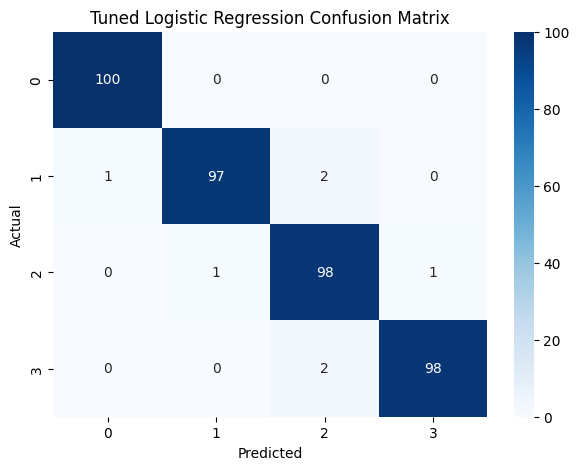

In [118]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate confusion matrix for the tuned Logistic Regression model
cm = confusion_matrix(y_test, y_pred_tuned)

plt.figure(figsize=(7, 5))

# Render the confusion matrix heatmap
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[0, 1, 2, 3],
    yticklabels=[0, 1, 2, 3]
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Tuned Logistic Regression Confusion Matrix')

plt.show()

## Tuned Classification Report

In [119]:
# Display the classification report containing detailed metrics for the tuned model
print(classification_report(y_test, y_pred_tuned))

              precision    recall  f1-score   support

           0       0.99      1.00      1.00       100
           1       0.99      0.97      0.98       100
           2       0.96      0.98      0.97       100
           3       0.99      0.98      0.98       100

    accuracy                           0.98       400
   macro avg       0.98      0.98      0.98       400
weighted avg       0.98      0.98      0.98       400



In [120]:
# Predict labels for the training set using the best estimator
y_train_pred = best_lr.predict(X_train_scaled)

# Compare and print Training and Testing accuracy to check for overfitting
print("Training Accuracy:",
      accuracy_score(y_train, y_train_pred))

print("Testing Accuracy:",
      accuracy_score(y_test, y_pred_tuned))

Training Accuracy: 0.98625
Testing Accuracy: 0.9825


## 18. Save the Final Model

The complete Pipeline contains both the scaler and the trained Logistic Regression model.

Therefore, save the Pipeline as one file.

In [121]:
import pickle

# Save the best Logistic Regression model classifier to a pickle file
with open("cellphone_price_model.pkl", "wb") as file:
    pickle.dump(best_lr, file)

# Save the fit scaler to normalize future data inputs identically
with open("scaler.pkl", "wb") as file:
    pickle.dump(scaler, file)

In [122]:
import pickle

# Save scaler under alternative clean name cellphone_scaler.pkl
with open("cellphone_scaler.pkl", "wb") as file:
    pickle.dump(scaler, file)

# Re-save the final trained model for clarity
with open("cellphone_price_model.pkl", "wb") as file:
    pickle.dump(best_lr, file)

print("Model and scaler saved successfully!")

Model and scaler saved successfully!


Load the Saved Model

In [123]:
# Load the saved scaler and model to simulate an inference environment
with open("cellphone_scaler.pkl", "rb") as file:
    loaded_scaler = pickle.load(file)

with open("cellphone_price_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

Test a Prediction

In [125]:
# Extract a single sample row from test set for test prediction
sample = X_test.iloc[[0]]

# Normalize the single sample features using our loaded standard scaler
sample_scaled = loaded_scaler.transform(sample)

# Run prediction using the loaded model
prediction = loaded_model.predict(sample_scaled)

# Verify correctness by printing predicted vs actual values
print("Predicted Price Range:", prediction[0])
print("Actual Price Range:", y_test.iloc[0])

Predicted Price Range: 3
Actual Price Range: 3


## 19. MODEL COMPARISON REPORT

### Objective

The objective of the model comparison is to evaluate multiple classification algorithms and identify the most suitable model for predicting cellphone price ranges.

### Models Evaluated

Seven classification algorithms were implemented:

Logistic Regression

K-Nearest Neighbors

Decision Tree

Random Forest

Support Vector Machine

Gaussian Naive Bayes

XGBoost








In [126]:
import pandas as pd

comparison = {
    "S.No": [1, 2, 3, 4, 5, 6, 7],
    "Model": [
        "Logistic Regression",
        "K-Nearest Neighbors (KNN)",
        "Decision Tree",
        "Random Forest",
        "Support Vector Machine (SVM)",
        "Gaussian Naive Bayes",
        "XGBoost"
    ],
    "Accuracy (%)": [96.50, 50.00, 83.00, 88.00, 89.50, 81.00, 91.25],
    "Precision (%)": [96.50, 52.11, 83.19, 87.96, 89.69, 81.13, 91.18],
    "Recall (%)": [96.50, 50.00, 83.00, 88.00, 89.50, 81.00, 91.25],
    "F1-Score (%)": [96.50, 50.54, 83.02, 87.97, 89.56, 81.05, 91.19]
}

comparison_df = pd.DataFrame(comparison)
display(comparison_df)

,S.No,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,1,Logistic Regression,96.50,96.50,96.50,96.50
1,2,K-Nearest Neighbors (KNN),50.00,52.11,50.00,50.54
2,3,Decision Tree,83.00,83.19,83.00,83.02
3,4,Random Forest,88.00,87.96,88.00,87.97
4,5,Support Vector Machine (SVM),89.50,89.69,89.50,89.56
5,6,Gaussian Naive Bayes,81.00,81.13,81.00,81.05
6,7,XGBoost,91.25,91.18,91.25,91.19


### Hyperparameter Tuning

Logistic Regression was selected for hyperparameter tuning because it achieved the highest initial accuracy.

GridSearchCV was used with five-fold cross-validation.

The best parameters in your earlier experiment were:

C = 100

Solver = lbfgs

Maximum iterations = 1000

The earlier tuned model achieved:

Training accuracy = 98.625%

Testing accuracy = 98.25%

F1-score = approximately 98%

The final Pipeline-based tuning should be run again before submitting the final report. Replace the earlier tuning results with the new results if they differ.

### Final Model Selection

Logistic Regression was selected as the best-performing model based on the results obtained in the initial comparison and the subsequent tuning experiment.

Reasons:

Highest initial accuracy among the tested models.

Strong precision, recall, and F1-score.

Good classification performance across all four categories.

Small difference between training and testing accuracy in the earlier experiment.

Hyperparameter tuning improved its earlier test performance.

## Selected model: Tuned Logistic Regression.

## 20. REPORT ON CHALLENGES FACED

During the Cellphone Price Range Prediction project, several challenges were encountered during data analysis, preprocessing, model building, and evaluation.

Explanation of Important Challenges

1. Understanding Feature Distributions

Initially, it was difficult to understand how cellphone specifications were distributed.

Solution: Histograms and boxplots were used to visualize the distributions and identify unusual values.

2. Outlier Detection

Some features contained potential outliers, especially front camera megapixels and pixel height.

Solution: The IQR method was applied. Potential outliers were investigated rather than automatically removed because they could represent genuine specifications.

3. Feature Scaling

Different features had different numerical ranges.

Solution: StandardScaler was used for Logistic Regression, KNN, and SVM. Tree-based models were trained without scaling.

4. Selecting the Best Model

Different classification algorithms produced different performance results.

Solution: Seven classification models were trained and compared using accuracy, precision, recall, and F1-score.

5. Improving Model Performance

The initial Logistic Regression model achieved 96.50% accuracy in the earlier experiment.

Solution: GridSearchCV was used to find better hyperparameter values. A Pipeline was used for leakage-safe cross-validation.

6. Model Evaluation

Accuracy alone does not fully explain the performance of a multiclass classification model.

Solution: Confusion matrices and classification reports were used to examine the predictions for each price category.

## 21. FUTURE ENHANCEMENTS

Build a web application using Flask or Streamlit.

Allow users to enter cellphone specifications.

Display the predicted price category.

Test the model with additional cellphone datasets.

Explore additional feature engineering techniques.

Monitor prediction performance on newer cellphone products.

## 22. FINAL CONCLUSION

The Cellphone Price Range Prediction project demonstrates the use of supervised Machine Learning classification algorithms to predict cellphone price categories based on technical specifications.

Data inspection, cleaning, exploratory data analysis, outlier detection, correlation analysis, feature scaling, model building, and evaluation were performed.

Seven classification algorithms were implemented and compared.

Logistic Regression achieved the highest initial accuracy of 96.50%. It was selected for hyperparameter tuning using GridSearchCV.

In the earlier tuning experiment, Logistic Regression achieved 98.25% testing accuracy and approximately 98% F1-score.

Therefore, Tuned Logistic Regression was selected as the best-performing model in the earlier experiment.

The project demonstrates how Machine Learning can help classify mobile phones into price categories based on their specifications.